# ANA-074 — Does interaction concentration improve TrpB resemblance?
RUN-190 fits Gamma variance concentration jointly with r and four readout parameters.
RUN-188 supplies the exact Gaussian and r=0 controls. The same profile, direct
calibration objective, shared-stop observation law, panels and seeds are retained.
The Gamma coefficients are sqrt(V) Z, V ~ Gamma(alpha, rate=alpha), Z ~ N(0,1),
followed by centering and mutation-RMS normalization. Alpha=100 is near Gaussian,
not exactly Gaussian. This notebook performs no fitting and draws no new noise.

Primary summaries use eight originally fresh generator seeds. All 24 are exported.
Dots and 10–90% ranges show generator variation, not confidence intervals or
biological replication. These TrpB panels were inspected previously: this is a
matched diagnostic comparison, not new independent empirical validation.

In [1]:
from pathlib import Path
import hashlib,json,sqlite3,importlib.metadata
from itertools import combinations
import numpy as np
import pandas as pd
from scipy.linalg import hadamard
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
import yaml
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'labproject.yaml').exists())
ANA=ROOT/'analyses/2026-11-25_ANA-074_run-190-gamma-concentration-versus-gaussian-trpb-calibration'
RUN=ROOT/'data/processed/aggregate-thermodynamic-gnk-calibration/RUN-190'
OUT=RUN/'outputs';FROZEN=RUN/'frozen_runtime';CONTROL=FROZEN/'baseline/RUN-188'
BASE=CONTROL/'frozen_runtime/baseline/RUN-186'
FIG=ANA/'figures';TAB=ANA/'tables'
for p in [FIG,TAB]:p.mkdir(exist_ok=True)
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False)+'\n')
assert sha(OUT/'manifest.json')=='778234f248075facda9b291d1a0fa453278f22d41e5ebb0ec4e8aa98486d1a88'
assert sha(FROZEN/'prelaunch_manifest.json')=='9537c18a56d5d8cf42b6516de6a84840210d4687861e4d6042b0792b457cab68'
manifest=json.loads((OUT/'manifest.json').read_text()); frozen=json.loads((FROZEN/'prelaunch_manifest.json').read_text())
for folder,m in [(OUT,manifest),(FROZEN,frozen)]:
    for name,digest in m['files'].items():assert sha(folder/name)==digest,name
for name in ['labproj-exit-code.txt','gamma-concentration-scientific-exit-code.txt']:
    assert (RUN/'logs'/name).read_text().strip()=='0'
assert not (RUN/'logs/stderr.txt').read_text()
settings=json.loads((OUT/'selected_parameters.json').read_text());byarm={s['arm']:s for s in settings}
old=json.loads((CONTROL/'outputs/selected_parameters.json').read_text())
for s in old:
    for k,v in s.items():assert byarm[s['arm']][k]==v
assert byarm['gamma']['parameters']==byarm['full']['parameters']
assert byarm['gamma']['ratio']==byarm['full']['ratio']==.5
assert byarm['gamma']['interaction_concentration']==100
con=sqlite3.connect(f'file:{OUT}/fits/gamma.sqlite3?mode=ro',uri=True)
assert dict(con.execute('select state,count(*) from trials group by state'))=={'COMPLETE':11712}
assert con.execute('select min(value) from trial_values').fetchone()[0]==byarm['gamma']['objective']['total'];con.close()
trials=pd.read_csv(OUT/'fits/gamma_trials.csv.gz',float_precision='round_trip')
assert len(trials)==11712 and trials.total.notna().all()
assert trials.total.idxmin()==7
fits=pd.DataFrame([dict(arm=s['arm'],r=s['ratio'],alpha=s.get('interaction_concentration'),**s['objective']) for s in settings]).set_index('arm')
fits.to_csv(TAB/'calibration.csv')
audit=pd.read_csv(OUT/'seed_audit.csv');fresh=audit[audit.cohort=='fresh'].seed.tolist()
assert len(audit)==24 and len(fresh)==8
scale=settings[0]['calibration_scale'];resolutions=np.array([0,.001,.01])*scale;eps=resolutions[1]
cutoffs=np.array([.05396940664223584,.05369397352521348])
read=lambda n:pd.read_csv(OUT/n,float_precision='round_trip')
cubes=read('cube_summary.csv.gz'); powers=read('cube_powers.csv.gz'); faces_saved=read('face_reproducibility.csv.gz')
reps=read('replicate_summary.csv'); graphs=read('static_graph_summary.csv'); dist=read('fitness_distribution.csv')
C={'r0':'#969696','full':'#2463A6','gamma':'#D66B21','empirical':'#202020'}
N={'r0':'r = 0 control','full':'Gaussian','gamma':'Gamma (α = 100)','empirical':'TrpB'}
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'savefig.dpi':180,'pdf.fonttype':42})
def save(fig,name):
    fig.savefig(FIG/(name+'.png'),bbox_inches='tight',facecolor='white')
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight',facecolor='white');display(fig);plt.close(fig)
def select(df,layer='observed',epsilon=eps):
    d=df[df.layer.eq(layer)&(df.seed.isin(fresh)|df.arm.eq('empirical'))]
    key='resolution' if 'resolution' in d else 'epsilon' if 'epsilon' in d else None
    return d[np.isclose(d[key],epsilon,rtol=1e-12,atol=1e-15)] if key else d

def comparison(ax,df,metric,title,ylabel='',empirical=None):
    for x,arm in enumerate(['r0','full','gamma']):
        v=df[df.arm.eq(arm)][metric].dropna().to_numpy()
        if len(v):
            lo,mid,hi=np.quantile(v,[.1,.5,.9]);ax.plot([x,x],[lo,hi],color=C[arm],lw=4,alpha=.4)
            ax.scatter(x+np.linspace(-.08,.08,len(v)),v,color=C[arm],s=18,zorder=3)
            ax.scatter([x],[mid],color=C[arm],marker='_',s=170,zorder=4)
    e=df[df.arm.eq('empirical')][metric].dropna() if empirical is None else np.atleast_1d(empirical)
    if len(e):ax.axhline(float(np.mean(e)),color=C['empirical'],ls='--',lw=1.4,label='TrpB')
    ax.set(xticks=range(3),xticklabels=['r = 0','Gaussian','Gamma'],title=title,ylabel=ylabel)
    ax.grid(axis='y',alpha=.15)
print('Verified',len(manifest['files']),'output files and',len(frozen['files']),'frozen files; 11,712 completed trials.')
display(fits)

Verified 65 output files and 536 frozen files; 11,712 completed trials.


,r,alpha,quantile,mean_sd,floor_cdf,total
arm,,,,,,
r0,0.0,NaN,0.041241,0.000814,0.000020,0.042075
full,0.5,NaN,0.029890,0.001101,0.000004,0.030995
gamma,0.5,100.0,0.030183,0.000843,0.000007,0.031032


## Independent numerical checks
Recompute Walsh powers, directed sign reversals, repeatability and the complete
101-quantile curves from the saved values. Gaussian/r0 cube values must match
RUN-188 byte-for-byte numerically. Parseval checks total power against variance.
Cross-powers are signed products, not squared coefficients; retain negatives.

In [2]:
H=hadamard(16).astype(float);orders=np.array([i.bit_count() for i in range(16)])
face_index=np.array([[s,s|1<<i,s|1<<j,s|1<<i|1<<j] for i,j in combinations(range(4),2) for s in range(16) if not s&((1<<i)|(1<<j))])
def signs(y,t):
    z=y[:,face_index];edges=np.stack([z[:,:,1]-z[:,:,0],z[:,:,3]-z[:,:,2],z[:,:,2]-z[:,:,0],z[:,:,3]-z[:,:,1]],axis=-1)
    s=np.where(edges>t,1,np.where(edges < -t,-1,0))
    flip=np.stack([s[:,:,0]*s[:,:,1]<0,s[:,:,2]*s[:,:,3]<0],axis=-1)
    return s,flip

def validate_values(a,b,q,label):
    p=powers
    d=dist
    f=faces_saved
    c=cubes
    for key,value in label.items():
        p=p[p[key].eq(value)];d=d[d[key].eq(value)];f=f[f[key].eq(value)];c=c[c[key].eq(value)]
    p=p.sort_values('cube');y=(a+b)/2
    c1,c2=a@H/16,b@H/16;cm=(c1+c2)/2
    for k in range(1,5):
        mask=orders==k
        for name,v in [('mean',(cm[:,mask]**2).sum(axis=1)),('cross',(c1[:,mask]*c2[:,mask]).sum(axis=1)),
                       ('stop_adjusted',(c1[:,mask]*c2[:,mask]).sum(axis=1)-mask.sum()*np.broadcast_to(q,a.shape).sum(axis=1)/256)]:
            np.testing.assert_allclose(p[f'{name}_power_{k}'],v,rtol=1e-10,atol=1e-18)
    np.testing.assert_allclose((cm[:,1:]**2).sum(axis=1),y.var(axis=1),rtol=1e-11,atol=1e-18)
    np.testing.assert_allclose(d[[f'q{q:03d}' for q in range(101)]].iloc[0],np.quantile(y,np.linspace(0,1,101)),rtol=1e-12,atol=1e-14)
    for t in resolutions:
        ff=f[np.isclose(f.epsilon,t,atol=1e-15,rtol=1e-12)].sort_values(['cube','face'])
        s1,f1=signs(a,t);s2,f2=signs(b,t);_,fm=signs(y,t)
        same=np.stack([(s1[:,:,:2]==s2[:,:,:2]).all(axis=-1),(s1[:,:,2:]==s2[:,:,2:]).all(axis=-1)],axis=-1)
        repeated=f1&f2&same
        for name,v in [('mean_sign',fm.any(axis=-1)),('mean_reciprocal',fm.all(axis=-1)),('reproducible_sign',repeated.any(axis=-1)),('reproducible_reciprocal',repeated.all(axis=-1))]:
            np.testing.assert_array_equal(ff[name],v.ravel())
        cc=c[np.isclose(c.resolution,t,atol=1e-15,rtol=1e-12)].sort_values('cube')
        np.testing.assert_allclose(cc.sd_fitness,y.std(axis=1),rtol=1e-12,atol=1e-14)
        np.testing.assert_allclose(cc.sign_epistasis_fraction,fm.any(axis=-1).mean(axis=-1),rtol=1e-12,atol=1e-14)
        slopes=[]
        for values in y:
            eligible=[]
            for site in range(4):
                low=np.array([i for i in range(16) if not (i&(1<<site))]);background=values[low]
                effect=values[low|(1<<site)]-background
                if background.var()>max(t*t,1e-24):
                    eligible.append(np.linalg.lstsq(np.column_stack([background,np.ones(8)]),effect,rcond=None)[0][0])
            slopes.append(float(np.mean(eligible)) if eligible else np.nan)
        np.testing.assert_allclose(cc.slope,slopes,rtol=1e-9,atol=1e-11,equal_nan=True)
    return len(a)
assert np.isclose(((2*H[1]+3*H[3])@H/16)[3]**2,9)
checked=0
with np.load(OUT/'empirical_replicates.npz') as z:
    empirical_values=(z['replicate_1']+z['replicate_2'])/2
    checked+=validate_values(z['replicate_1'],z['replicate_2'],z['shared_covariance'],dict(arm='empirical',seed=-1,layer='observed'))
for row in audit.itertuples(index=False):
    with np.load(OUT/'confirmation'/f'TrpB_{row.seed}.npz') as z, np.load(CONTROL/'outputs/confirmation'/f'TrpB_{row.seed}.npz') as oldz:
        for name in oldz.files:np.testing.assert_array_equal(z[name],oldz[name])
        for arm in ['r0','full','gamma']:
            raw=z[f'{arm}_intrinsic']
            checked+=validate_values(raw,raw,0,dict(arm=arm,seed=row.seed,layer='intrinsic'))
            checked+=validate_values(z[f'{arm}_replicate_1'],z[f'{arm}_replicate_2'],z[f'{arm}_shared_covariance'],dict(arm=arm,seed=row.seed,layer='observed'))
assert checked==1184
validation=dict(output_files=len(manifest['files']),frozen_files=len(frozen['files']),completed_trials=11712,
    independently_checked_cube_layer_rows=checked,independent_checks=['Walsh mean/cross/stop-adjusted power','Parseval','101 quantiles','cube SD','diminishing-return slopes via least squares','directed sign reversals at all three resolutions','replicate-consistent signs'],gaussian_and_null_replay='exact on all 24 seeds',new_fitting=False,new_noise=False)
dump(TAB/'validation.json',validation)
print('Independent checks passed for',checked,'cube/layer rows and',len(faces_saved),'face/resolution rows.')

Independent checks passed for 1184 cube/layer rows and 85248 face/resolution rows.


## 1. Calibration: the selected candidate is almost Gaussian
All 11,712 trials completed. Trial 7 was a queued historical readout at alpha=100.
No later proposal improved it. The exact Gaussian control is separate from this
finite-alpha family. The alpha/loss scatter changes all six coordinates at once:
it is not a profile likelihood or a controlled alpha-response curve.

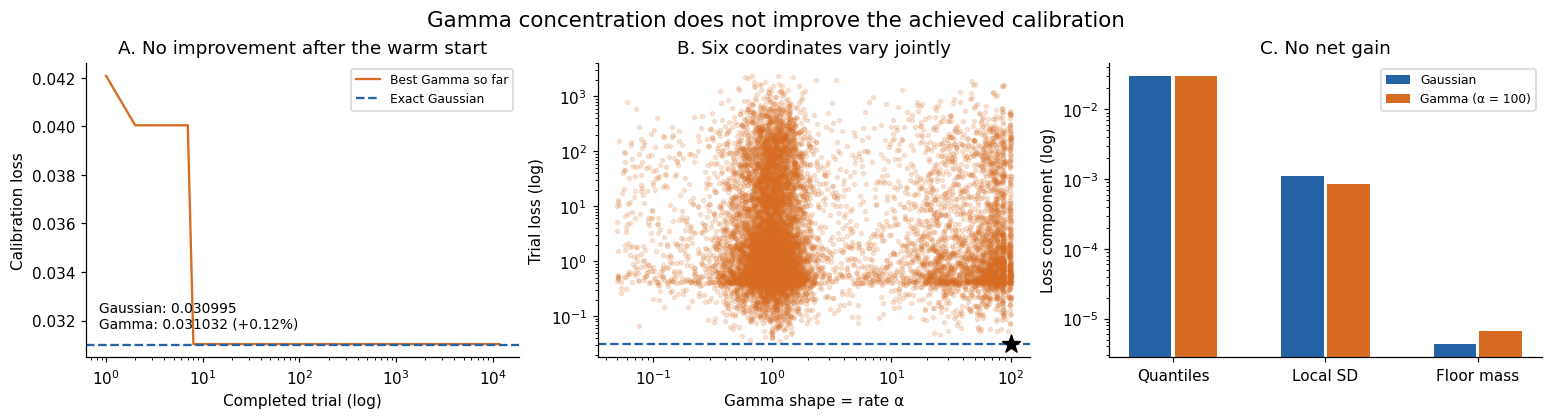

In [3]:
fig,ax=plt.subplots(1,3,figsize=(14,3.7),layout='constrained')
ax[0].plot(trials.trial+1,trials.total.cummin(),color=C['gamma'],label='Best Gamma so far')
ax[0].axhline(fits.loc['full','total'],color=C['full'],ls='--',label='Exact Gaussian')
ax[0].set(xscale='log',xlabel='Completed trial (log)',ylabel='Calibration loss',title='A. No improvement after the warm start');ax[0].legend(fontsize=8)
ax[0].text(.03,.1,'Gaussian: 0.030995\nGamma: 0.031032 (+0.12%)',transform=ax[0].transAxes,fontsize=9)
ax[1].scatter(trials.alpha,trials.total,s=7,alpha=.16,color=C['gamma'],rasterized=True)
ax[1].scatter([100],[fits.loc['gamma','total']],marker='*',s=150,color='black',zorder=5)
ax[1].axhline(fits.loc['full','total'],color=C['full'],ls='--')
ax[1].set(xscale='log',yscale='log',xlabel='Gamma shape = rate α',ylabel='Trial loss (log)',title='B. Six coordinates vary jointly')
for i,metric in enumerate(['quantile','mean_sd','floor_cdf']):
    for j,arm in enumerate(['full','gamma']):ax[2].bar(i+(j-.5)*.3,fits.loc[arm,metric],width=.28,color=C[arm],label=N[arm] if i==0 else None)
ax[2].set(yscale='log',xticks=range(3),xticklabels=['Quantiles','Local SD','Floor mass'],ylabel='Loss component (log)',title='C. No net gain');ax[2].legend(fontsize=8)
fig.suptitle('Gamma concentration does not improve the achieved calibration',fontsize=14)
save(fig,'01_calibration')

## Aggregate tables for all seeds, cohorts and resolutions
Cube fractions are averaged equally; pooled powers are summed before division.
Both are retained because high-variance cubes can dominate pooled fractions.
A seed is the unit for paired contrasts. Empirical values pool 32 confirmation
cubes; each synthetic seed uses eight assigned cubes, so spread includes panel variation.

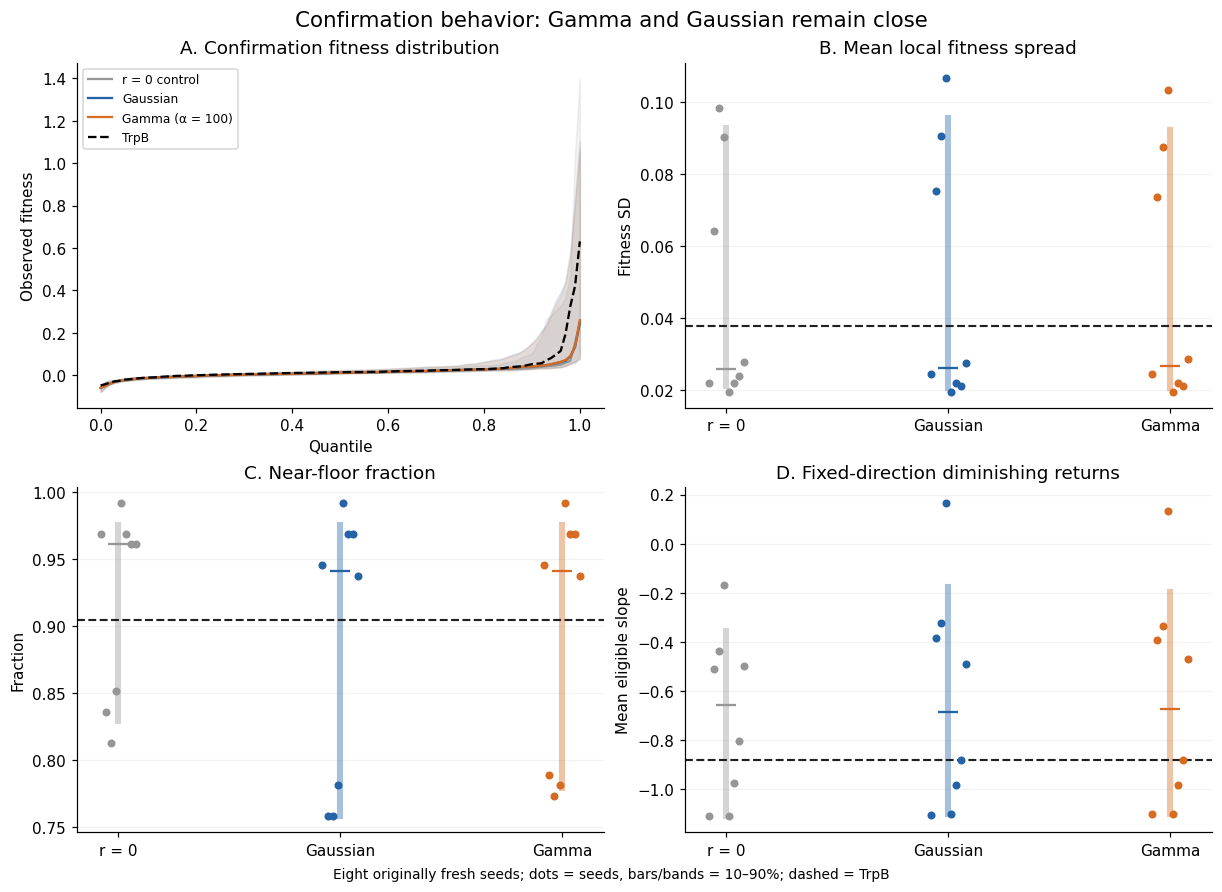

In [4]:
keys=['arm','seed','cohort','layer','resolution']
means=['mean_fitness','sd_fitness','near_floor_fraction','epistatic_fraction','ho_fraction','sign_epistasis_fraction','reciprocal_sign_epistasis_fraction','slope','beneficial_slope','neutral_edge_fraction']
summary=cubes.groupby(keys,dropna=False)[means].mean().reset_index()
ps=cubes.groupby(keys)[['power_1','power_2','power_3','power_4']].sum();den=ps.sum(axis=1)
ps['pooled_epistatic_fraction']=(ps.power_2+ps.power_3+ps.power_4)/den
ps['pooled_ho_fraction']=(ps.power_3+ps.power_4)/den
summary=summary.merge(ps[['pooled_epistatic_fraction','pooled_ho_fraction']].reset_index(),on=keys)
repeat=reps[reps.stratum.eq('all')].rename(columns={'epsilon':'resolution'})
summary=summary.merge(repeat[keys+['reproducible_sign','reproducible_reciprocal','cross_power_2','cross_power_3','cross_power_4']],on=keys)
summary.to_csv(TAB/'seed_summary.csv',index=False)
summary.groupby(['cohort','arm','layer','resolution'])[means+['pooled_epistatic_fraction','pooled_ho_fraction','reproducible_sign']].agg(['median','min','max']).to_csv(TAB/'cohort_summary.csv')
primary=select(summary)
fig,ax=plt.subplots(2,2,figsize=(11,8),layout='constrained')
x=np.linspace(0,1,101)
for arm in ['r0','full','gamma']:
    q=select(dist);q=q[q.arm.eq(arm)][[f'q{i:03d}' for i in range(101)]].to_numpy()
    lo,mid,hi=np.quantile(q,[.1,.5,.9],axis=0)
    ax[0,0].plot(x,mid,color=C[arm],label=N[arm]);ax[0,0].fill_between(x,lo,hi,color=C[arm],alpha=.12)
e=dist[dist.arm.eq('empirical')][[f'q{i:03d}' for i in range(101)]].iloc[0]
ax[0,0].plot(x,e,color='black',ls='--',label='TrpB');ax[0,0].set(xlabel='Quantile',ylabel='Observed fitness',title='A. Confirmation fitness distribution');ax[0,0].legend(fontsize=8)
comparison(ax[0,1],primary,'sd_fitness','B. Mean local fitness spread','Fitness SD')
comparison(ax[1,0],primary,'near_floor_fraction','C. Near-floor fraction','Fraction')
comparison(ax[1,1],primary,'slope','D. Fixed-direction diminishing returns','Mean eligible slope')
fig.suptitle('Confirmation behavior: Gamma and Gaussian remain close',fontsize=14)
fig.supxlabel('Eight originally fresh seeds; dots = seeds, bars/bands = 10–90%; dashed = TrpB',fontsize=9)
save(fig,'02_fitness_and_diminishing_returns')

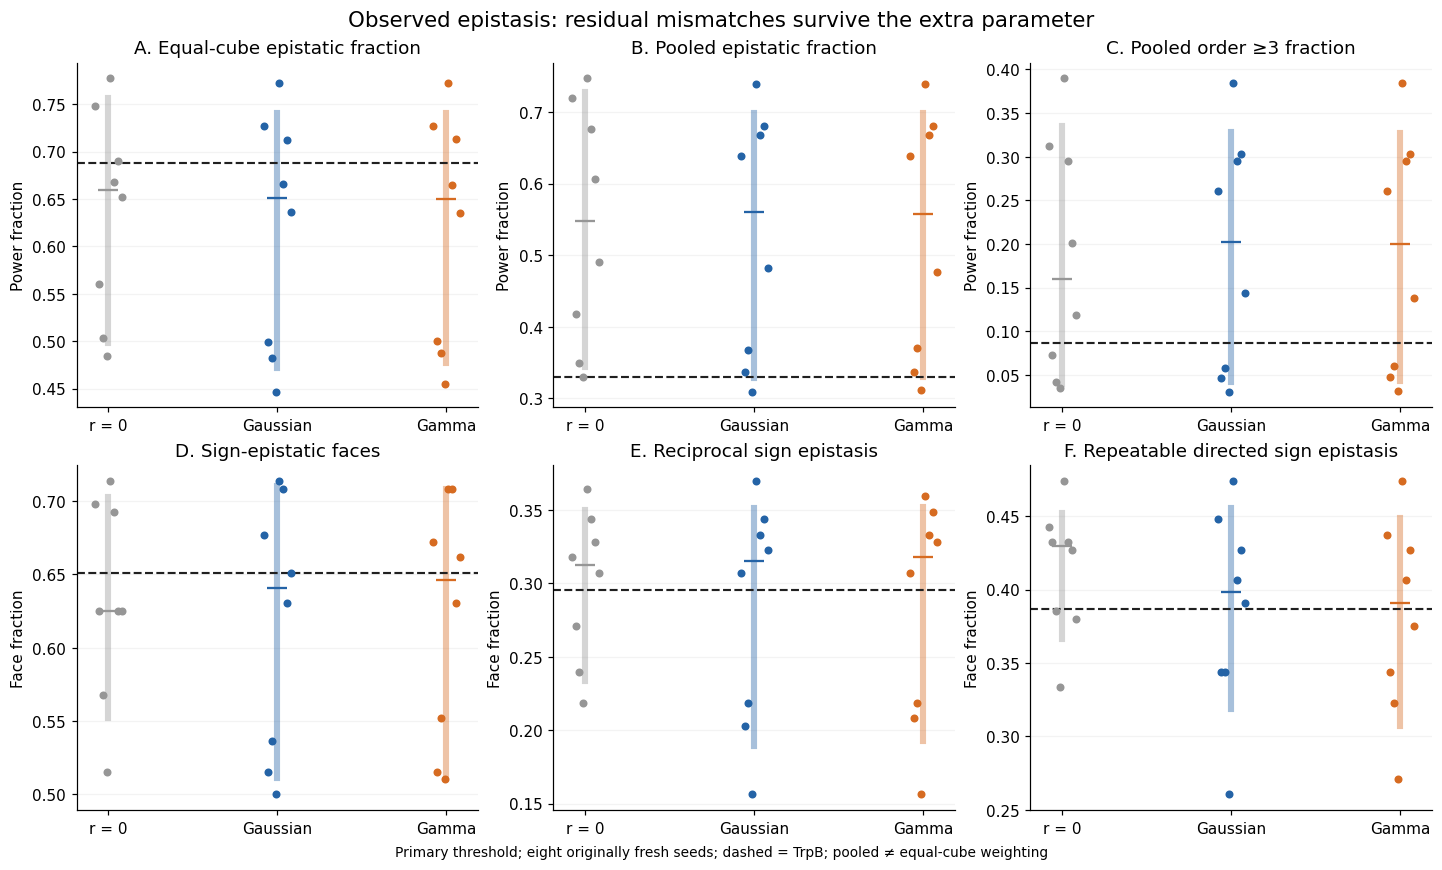

In [5]:
fig,ax=plt.subplots(2,3,figsize=(13,7.8),layout='constrained')
for a,metric,title in zip(ax[0],['epistatic_fraction','pooled_epistatic_fraction','pooled_ho_fraction'],['A. Equal-cube epistatic fraction','B. Pooled epistatic fraction','C. Pooled order ≥3 fraction']):
    comparison(a,primary,metric,title,'Power fraction')
for a,metric,title in zip(ax[1],['sign_epistasis_fraction','reciprocal_sign_epistasis_fraction','reproducible_sign'],['D. Sign-epistatic faces','E. Reciprocal sign epistasis','F. Repeatable directed sign epistasis']):
    comparison(a,primary,metric,title,'Face fraction')
fig.suptitle('Observed epistasis: residual mismatches survive the extra parameter',fontsize=14)
fig.supxlabel('Primary threshold; eight originally fresh seeds; dashed = TrpB; pooled ≠ equal-cube weighting',fontsize=9)
save(fig,'03_epistasis')

## Replicate-aware architecture and activity coverage
Shared error survives cross-replicate products. These coefficients describe
observable four-site binary cubes, not inferred sequence-specific biological
pair tables. Intrinsic means after the sigmoid, before observation noise.
Activity strata can differ between arms; sparse all-active faces limit interpretation.

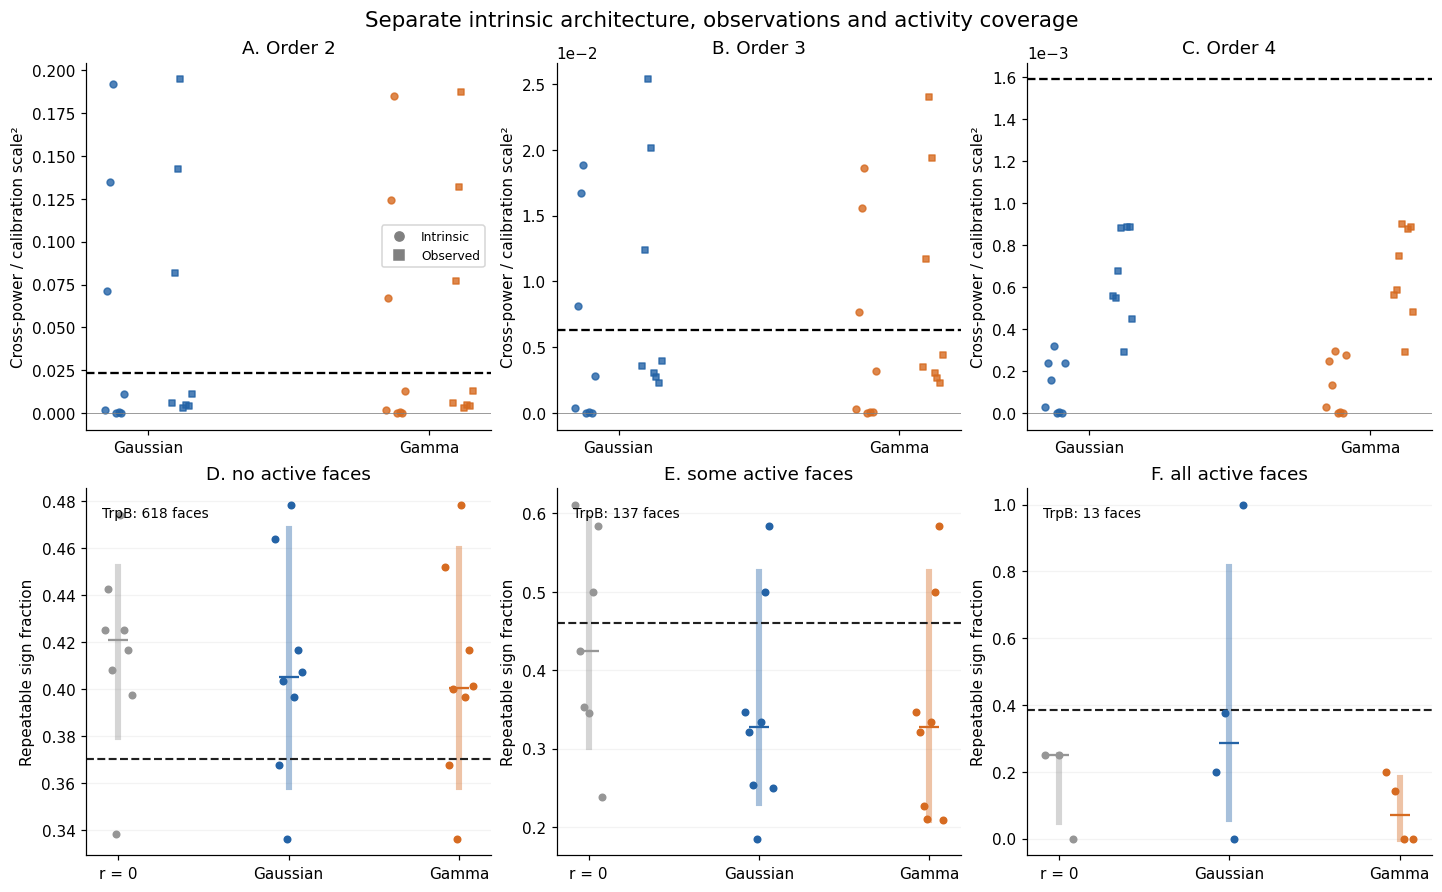

In [6]:
fig,ax=plt.subplots(2,3,figsize=(13,8),layout='constrained')
for j,k in enumerate([2,3,4]):
    for layer,marker,offset in [('intrinsic','o',-.12),('observed','s',.12)]:
        for i,arm in enumerate(['full','gamma']):
            v=select(reps,layer);v=v[v.arm.eq(arm)&v.stratum.eq('all')][f'cross_power_{k}']
            ax[0,j].scatter(i+offset+np.linspace(-.035,.035,len(v)),v/scale**2,marker=marker,color=C[arm],s=20,alpha=.8)
    e=select(reps);v=e[e.arm.eq('empirical')&e.stratum.eq('all')][f'cross_power_{k}'].iloc[0]/scale**2
    ax[0,j].axhline(v,ls='--',color='black');ax[0,j].axhline(0,color='grey',lw=.5)
    ax[0,j].set(xticks=[0,1],xticklabels=['Gaussian','Gamma'],ylabel='Cross-power / calibration scale²',title=f'{"ABC"[j]}. Order {k}')
    ax[0,j].ticklabel_format(axis='y',style='sci',scilimits=(-2,2))
for j,stratum in enumerate(['no_active','some_active','all_active']):
    d=select(reps);d=d[d.stratum.eq(stratum)]
    comparison(ax[1,j],d,'reproducible_sign',f'{"DEF"[j]}. {stratum.replace("_"," ")} faces','Repeatable sign fraction')
    e=d[d.arm.eq('empirical')].iloc[0];ax[1,j].text(.04,.95,f'TrpB: {int(e.n_faces)} faces',transform=ax[1,j].transAxes,va='top',fontsize=9)
ax[0,0].legend(handles=[Line2D([],[],marker='o',ls='',color='grey',label='Intrinsic'),Line2D([],[],marker='s',ls='',color='grey',label='Observed')],fontsize=8)
fig.suptitle('Separate intrinsic architecture, observations and activity coverage',fontsize=14)
save(fig,'04_repeatable_architecture')
reps.to_csv(TAB/'replicate_summary_all_seeds.csv',index=False)

## Static difficulty proxies, without running a learner or search policy
Neighbor correlation and mutation RMS describe local roughness. No-beneficial-
neighbor fraction describes local stopping points at the declared threshold.
These are not sample complexity, search success, basin sizes or walk lengths.
Graphs cover the common 159,129 observed genotypes; they include calibration nodes.

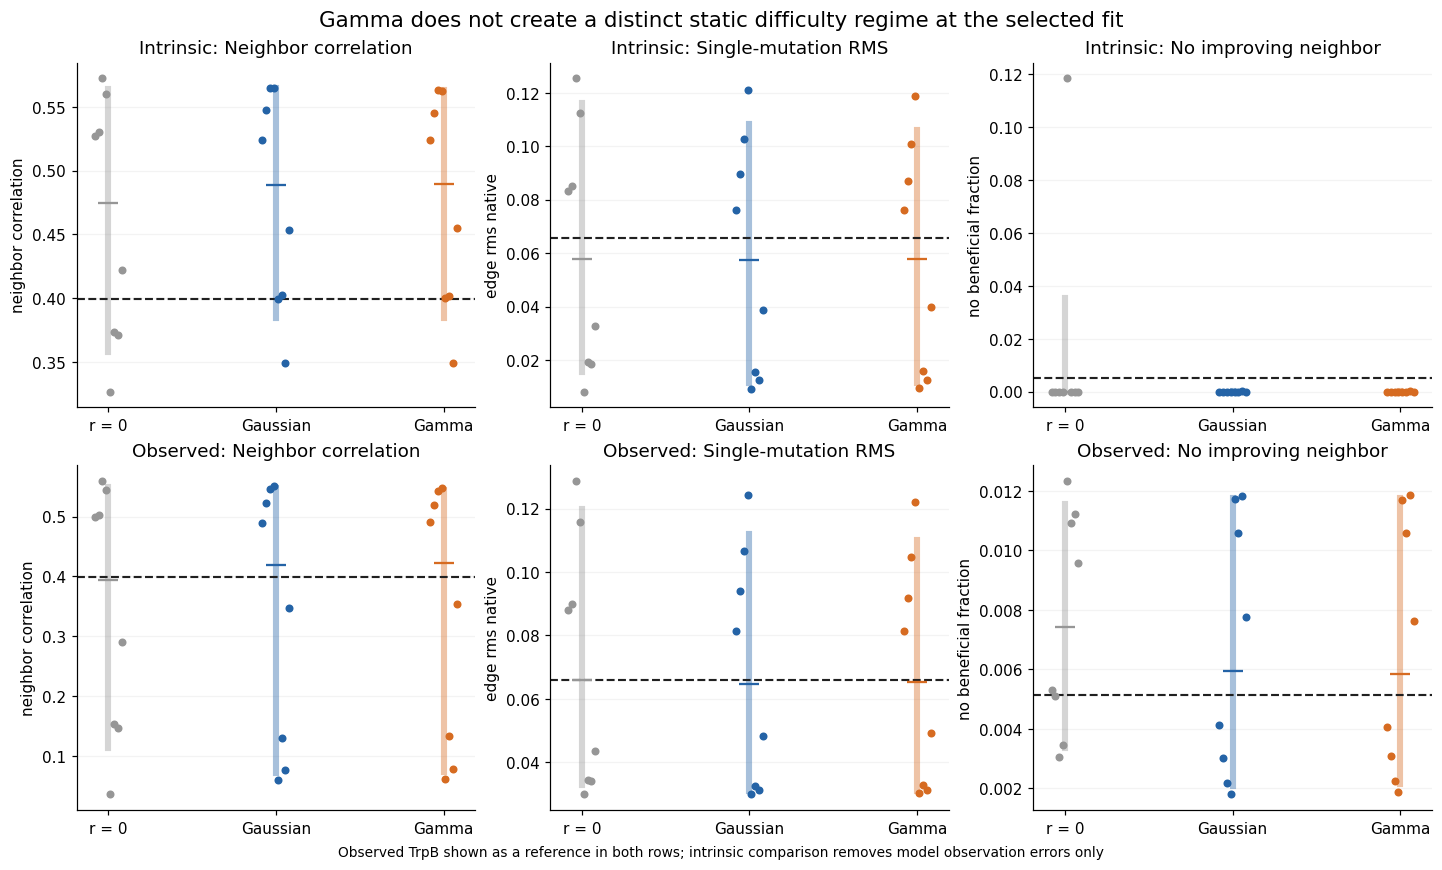

In [7]:
fig,ax=plt.subplots(2,3,figsize=(13,7.8),layout='constrained')
for i,layer in enumerate(['intrinsic','observed']):
    d=select(graphs,layer)
    empirical=select(graphs);empirical=empirical[empirical.arm.eq('empirical')]
    for j,(metric,title) in enumerate([('neighbor_correlation','Neighbor correlation'),('edge_rms_native','Single-mutation RMS'),('no_beneficial_fraction','No improving neighbor')]):
        comparison(ax[i,j],d,metric,f'{layer.capitalize()}: {title}',metric.replace('_',' '),empirical[metric].iloc[0])
fig.suptitle('Gamma does not create a distinct static difficulty regime at the selected fit',fontsize=14)
fig.supxlabel('Observed TrpB shown as a reference in both rows; intrinsic comparison removes model observation errors only',fontsize=9)
save(fig,'05_static_difficulty')
graphs.to_csv(TAB/'static_graph_all_seeds.csv',index=False)

## What happened to the underlying interaction tables?
Recover exact centered pair tables from the saved complete latent interaction
fields by uniform marginalization. For g(x)=constant+sum T_ij, averaging over
all other sites recovers T_ij plus the constant. This is an algebraic audit of
archived maps, not a fitted biological interaction model. Verify reconstruction
and zero row/column means. Normalization leaves concentration metrics unchanged.

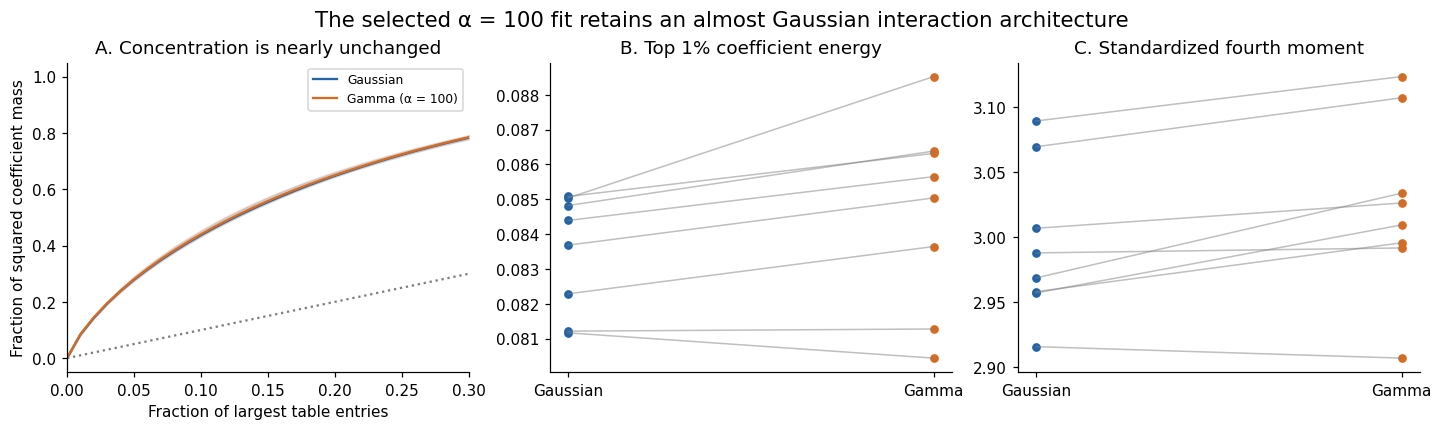

In [8]:
architecture=[];lorenz=[]
pairs=list(combinations(range(4),2))
for row in audit.itertuples(index=False):
    all_tables={}
    for arm,path in [('full',BASE/'outputs/latent_fields'/f'TrpB_{row.seed}.npz'),('gamma',OUT/'latent_fields'/f'TrpB_{row.seed}.npz')]:
        with np.load(path) as z:g=z['g'].reshape((20,)*4)
        tables=[];reconstructed=np.full_like(g,g.mean())
        for i,j in pairs:
            table=g.mean(axis=tuple(k for k in range(4) if k not in (i,j)))-g.mean()
            np.testing.assert_allclose(table.mean(axis=0),0,atol=1e-13);np.testing.assert_allclose(table.mean(axis=1),0,atol=1e-13)
            dims=[1]*4;dims[i]=dims[j]=20;reconstructed+=table.reshape(dims);tables.append(table)
        np.testing.assert_allclose(reconstructed,g,atol=2e-13,rtol=1e-12)
        a=np.stack(tables).ravel();energy=np.sort(a*a)[::-1];cumulative=np.r_[0,np.cumsum(energy)/energy.sum()]
        all_tables[arm]=a
        architecture.append(dict(seed=row.seed,cohort=row.cohort,arm=arm,top1pct_energy=float(energy[:24].sum()/energy.sum()),
            top10pct_energy=float(energy[:240].sum()/energy.sum()),standardized_fourth_moment=float(np.mean(a**4)/np.mean(a*a)**2)))
        for f in np.linspace(0,1,101):lorenz.append(dict(seed=row.seed,cohort=row.cohort,arm=arm,fraction=f,energy=float(cumulative[int(round(f*2400))])))
    architecture[-1]['paired_coefficient_correlation']=float(np.corrcoef(all_tables['full'],all_tables['gamma'])[0,1])
architecture=pd.DataFrame(architecture);lorenz=pd.DataFrame(lorenz)
architecture.to_csv(TAB/'latent_pair_table_concentration.csv',index=False);lorenz.to_csv(TAB/'latent_pair_table_energy_curves.csv',index=False)
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
for arm in ['full','gamma']:
    d=lorenz[lorenz.cohort.eq('fresh')&lorenz.arm.eq(arm)].pivot(index='seed',columns='fraction',values='energy')
    lo,mid,hi=np.quantile(d,[.1,.5,.9],axis=0)
    ax[0].plot(d.columns,mid,color=C[arm],label=N[arm]);ax[0].fill_between(d.columns,lo,hi,color=C[arm],alpha=.15)
ax[0].plot([0,1],[0,1],ls=':',color='grey');ax[0].set(xlim=(0,.3),xlabel='Fraction of largest table entries',ylabel='Fraction of squared coefficient mass',title='A. Concentration is nearly unchanged');ax[0].legend(fontsize=8)
for j,metric,title in [(1,'top1pct_energy','B. Top 1% coefficient energy'),(2,'standardized_fourth_moment','C. Standardized fourth moment')]:
    p=architecture[architecture.cohort.eq('fresh')].pivot(index='seed',columns='arm',values=metric)
    for _,v in p.iterrows():ax[j].plot([0,1],v[['full','gamma']],color='grey',alpha=.5,lw=1)
    for i,arm in enumerate(['full','gamma']):ax[j].scatter(np.full(len(p),i),p[arm],color=C[arm],s=22)
    ax[j].set(xticks=[0,1],xticklabels=['Gaussian','Gamma'],title=title)
fig.suptitle('The selected α = 100 fit retains an almost Gaussian interaction architecture',fontsize=14)
save(fig,'06_latent_concentration')

## Paired improvement and threshold sensitivity
For each seed calculate |Gamma − TrpB| − |Gaussian − TrpB|; negative means
Gamma is closer. Normalize only for the heatmap by max(|TrpB|, Gaussian seed
SD, 1e−12), using sample SD (ddof=1). This is a plotting scale, not a new loss.
No p-values or equivalence test: models share fields, noise uniforms and history.

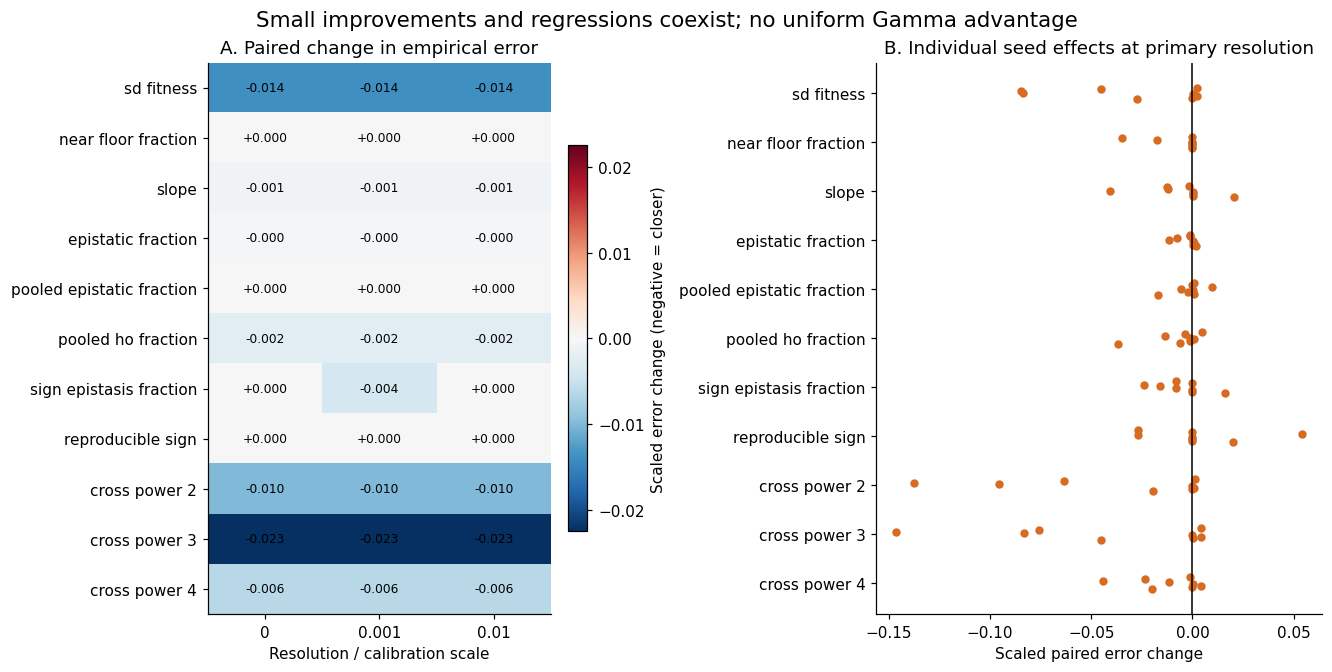

In [9]:
metrics=['sd_fitness','near_floor_fraction','slope','epistatic_fraction','pooled_epistatic_fraction','pooled_ho_fraction','sign_epistasis_fraction','reproducible_sign','cross_power_2','cross_power_3','cross_power_4']
contrasts=[]
for t in resolutions:
    d=select(summary,epsilon=t)
    empirical=d[d.arm.eq('empirical')].iloc[0]
    for metric in metrics:
        p=d[d.arm.isin(['full','gamma'])].pivot(index='seed',columns='arm',values=metric)
        target=float(empirical[metric]);denom=max(abs(target),float(p['full'].std()),1e-12)
        for seed,row in p.iterrows():
            delta=abs(row['gamma']-target)-abs(row['full']-target)
            contrasts.append(dict(seed=int(seed),relative_resolution=float(t/scale),metric=metric,empirical=target,gaussian=float(row['full']),gamma=float(row['gamma']),signed_model_difference=float(row['gamma']-row['full']),error_difference=float(delta),scaled_error_difference=float(delta/denom)))
contrasts=pd.DataFrame(contrasts);contrasts.to_csv(TAB/'paired_fresh_seed_contrasts.csv',index=False)
contrast_summary=contrasts.groupby(['relative_resolution','metric']).agg(median_error_difference=('error_difference','median'),median_scaled_difference=('scaled_error_difference','median'),gamma_closer=('error_difference',lambda x:int((x < -1e-14).sum())),n=('seed','size')).reset_index()
contrast_summary.to_csv(TAB/'paired_error_summary.csv',index=False)
heat=contrast_summary.pivot(index='metric',columns='relative_resolution',values='median_scaled_difference').reindex(metrics)
fig,ax=plt.subplots(1,2,figsize=(12,6),layout='constrained',gridspec_kw={'width_ratios':[1,1.3]})
vmax=max(abs(heat.to_numpy()).max(),.001)
im=ax[0].imshow(heat,cmap='RdBu_r',vmin=-vmax,vmax=vmax,aspect='auto')
ax[0].set(xticks=range(3),xticklabels=['0','0.001','0.01'],yticks=range(len(metrics)),yticklabels=[m.replace('_',' ') for m in metrics],xlabel='Resolution / calibration scale',title='A. Paired change in empirical error')
for i in range(len(metrics)):
    for j in range(3):ax[0].text(j,i,f'{heat.iloc[i,j]:+.3f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax[0],label='Scaled error change (negative = closer)',shrink=.7)
d=contrasts[np.isclose(contrasts.relative_resolution,.001)]
for i,m in enumerate(metrics):
    v=d[d.metric.eq(m)].scaled_error_difference
    ax[1].scatter(v,i+np.linspace(-.12,.12,len(v)),color=C['gamma'],s=20)
ax[1].axvline(0,color='black',lw=1);ax[1].set(yticks=range(len(metrics)),yticklabels=[m.replace('_',' ') for m in metrics],xlabel='Scaled paired error change',title='B. Individual seed effects at primary resolution');ax[1].invert_yaxis()
ax[1].xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(5))
fig.suptitle('Small improvements and regressions coexist; no uniform Gamma advantage',fontsize=14)
save(fig,'07_paired_comparison')

In [10]:
keyrows=[]
for metric in metrics:
    e=float(primary[primary.arm.eq('empirical')][metric].iloc[0])
    row=dict(metric=metric,empirical=e)
    for arm in ['r0','full','gamma']:
        v=primary[primary.arm.eq(arm)][metric].to_numpy()
        row.update({arm+'_median':float(np.nanmedian(v)),arm+'_p10':float(np.nanquantile(v,.1)),arm+'_p90':float(np.nanquantile(v,.9))})
    keyrows.append(row)
keytable=pd.DataFrame(keyrows);keytable.to_csv(TAB/'primary_comparison.csv',index=False)
arch=architecture[architecture.cohort.eq('fresh')].groupby('arm').median(numeric_only=True)
key=dict(gaussian_loss=float(fits.loc['full','total']),gamma_loss=float(fits.loc['gamma','total']),
    relative_loss_change=float(fits.loc['gamma','total']/fits.loc['full','total']-1),selected_alpha=100.,selected_r=.5,
    selected_trial=7,total_trials=11712,primary_seeds=8,all_seeds=24,
    coefficient_correlation_median=float(arch.loc['gamma','paired_coefficient_correlation']),
    gaussian_top1pct_energy=float(arch.loc['full','top1pct_energy']),gamma_top1pct_energy=float(arch.loc['gamma','top1pct_energy']),
    original_fresh_seeds_previously_inspected=True,new_independent_empirical_validation=False)
dump(TAB/'key_numbers.json',key)
dump(TAB/'analysis_environment.json',dict(python=__import__('platform').python_version(),packages={n:importlib.metadata.version(n) for n in ['numpy','pandas','scipy','matplotlib','nbformat','nbclient','ipykernel','PyYAML']},inputs_manifest_sha256=sha(OUT/'manifest.json')))
assert len(list(FIG.glob('*.png')))==7 and len(list(FIG.glob('*.pdf')))==7
validation.update(latent_pair_fields_reconstructed=48,figures=7)
dump(TAB/'validation.json',validation)
display(keytable)
print(json.dumps(key,indent=2))

,metric,empirical,r0_median,r0_p10,r0_p90,full_median,full_p10,full_p90,gamma_median,gamma_p10,gamma_p90
0,sd_fitness,0.037872,0.025823,0.021085,0.092744,0.025990,0.020449,0.095535,0.026463,0.020458,0.092340
1,near_floor_fraction,0.904297,0.960938,0.828906,0.975781,0.941406,0.757812,0.975781,0.941406,0.778906,0.975781
2,slope,-0.880500,-0.657000,-1.108050,-0.354836,-0.683886,-1.101362,-0.176682,-0.674880,-1.101009,-0.194739
3,epistatic_fraction,0.687570,0.659926,0.497625,0.756935,0.650948,0.471397,0.740793,0.650057,0.477372,0.740354
4,pooled_epistatic_fraction,0.329701,0.548177,0.344071,0.727706,0.560528,0.329231,0.698188,0.557821,0.329753,0.698386
5,pooled_ho_fraction,0.086173,0.159728,0.039579,0.335416,0.201800,0.042089,0.327825,0.199604,0.042480,0.327257
6,sign_epistasis_fraction,0.651042,0.625000,0.552083,0.702604,0.640625,0.510938,0.709896,0.645833,0.514062,0.708333
7,reproducible_sign,0.386719,0.429688,0.366146,0.452083,0.398438,0.318750,0.455729,0.390625,0.307292,0.448437
8,cross_power_2,0.000882,0.000396,0.000153,0.007674,0.000322,0.000148,0.005938,0.000349,0.000149,0.005583
9,cross_power_3,0.000237,0.000129,0.000096,0.000883,0.000142,0.000098,0.000816,0.000149,0.000097,0.000781


{
  "gaussian_loss": 0.03099516773204625,
  "gamma_loss": 0.031032134854951786,
  "relative_loss_change": 0.0011926737491829709,
  "selected_alpha": 100.0,
  "selected_r": 0.5,
  "selected_trial": 7,
  "total_trials": 11712,
  "primary_seeds": 8,
  "all_seeds": 24,
  "coefficient_correlation_median": 0.9987532123942399,
  "gaussian_top1pct_energy": 0.08403534220669714,
  "gamma_top1pct_energy": 0.08534210754480934,
  "original_fresh_seeds_previously_inspected": true,
  "new_independent_empirical_validation": false
}


## Interpretation
The extra concentration coordinate does not improve achieved calibration. The
optimizer retains a near-Gaussian queued candidate with the same r/readout as
the Gaussian control. Paired confirmation changes are small and metric-dependent;
statistical resemblance remains conditional on the observation layer and seed.
This does not show that lower alpha can never help, that alpha is identified,
or that the optimizer found a global optimum. No model default is changed.
TrpB-like aggregate descriptors and static proxies do not establish ML learning
efficiency, optimization success, long-sequence transfer or biological mechanisms.